# Issue #338 — QEU threshold activation on fixed N7

Executed decision notebook over the committed compact result package.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd().parents[2]
OUT=ROOT/'results/qeu_threshold_n7'

In [2]:
decision=json.loads((OUT/'decision.json').read_text())
performance=pd.read_csv(OUT/'performance.csv')
risk=pd.read_csv(OUT/'risk_diagnostics.csv')
selection=pd.read_csv(OUT/'development_selection.csv')
decision

{'causal_caveat': '2024 is previously exposed historical transfer evidence',
 'contract': 'BJ-UNIFIED-QEU-THRESHOLD-N7-001/v1',
 'development_ex_largest_fraction': None,
 'development_ex_largest_lift_r0_cny': -3841.202962379859,
 'development_lift_r0_cny': -12899.402778030752,
 'development_lift_r3_cny': -74243.62391033303,
 'excluded_issues': 14,
 'excluded_r3_action_different_issues': 13,
 'full_schedule_coverage': False,
 'issue': 338,
 'n_frozen': 7,
 'payout_factor_application': 'ticket_level_once',
 'promotable_to_210': False,
 'robustness_improved_vs_r3': False,
 'schedule_issues': 119,
 'selected_threshold_on_2023': 'RAW_Q80',
 'settled_issues': 105,
 'transfer_bootstrap_positive_fraction': 0.0885,
 'transfer_ex_largest_fraction': None,
 'transfer_ex_largest_lift_r0_cny': -13076.08496453296,
 'transfer_lift_r0_cny': -24916.285545313644,
 'transfer_lift_r3_cny': -91728.47174572057,
 'transfer_path_not_worse_than_r3': True,
 'verdict': 'FIXED_R3_REMAINS_BEST'}

In [3]:
selected=decision['selected_threshold_on_2023']
performance[performance.arm.isin(['R0','R3_CORRECTED',selected])]

,arm,kind,issue_year,issues,stake_cny,gross_cny,pnl_cny,ending_capital_cny,capital_return,stake_roi,...,hit_rate,miss_by_1_issues,miss_by_2_issues,matched_lift_r0_cny,matched_lift_r3_cny,ex_largest_lift_r0_cny,ex_largest_lift_r3_cny,largest_payout_share,mean_activated_changes,mean_baseline_overlap_fraction
6,R0,control,2023,47,48128,34598.374756,-13529.625244,86470.374756,-0.135296,-0.281118,...,0.234043,17,15,0.000000,-61344.221132,0.000000,-405.839021,0.261810,0.000000,1.000000
7,R0,control,2024,58,59392,73661.187609,14269.187609,114269.187609,0.142692,0.240254,...,0.344828,18,16,0.000000,-66812.186200,0.000000,-29497.660626,0.160739,0.000000,1.000000
8,R3_CORRECTED,fixed_rank,2023,47,48128,95942.595888,47814.595888,147814.595888,0.478146,0.993488,...,0.191489,16,12,61344.221132,0.000000,405.839021,0.000000,0.635155,1.957447,0.335106
9,R3_CORRECTED,fixed_rank,2024,58,59392,140473.373809,81081.373810,181081.373809,0.810814,1.365190,...,0.241379,19,18,66812.186200,0.000000,29497.660626,0.000000,0.265634,2.396552,0.230603
16,RAW_Q80,raw,2023,47,48128,21698.971978,-26429.028022,73570.971978,-0.264290,-0.549140,...,0.170213,21,11,-12899.402778,-74243.623910,-3841.202962,-13305.241799,0.300475,0.851064,0.648936
17,RAW_Q80,raw,2024,58,59392,48744.902064,-10647.097936,89352.902064,-0.106471,-0.179268,...,0.258621,24,17,-24916.285545,-91728.471746,-13076.084964,-54413.946171,0.176080,1.086207,0.605065


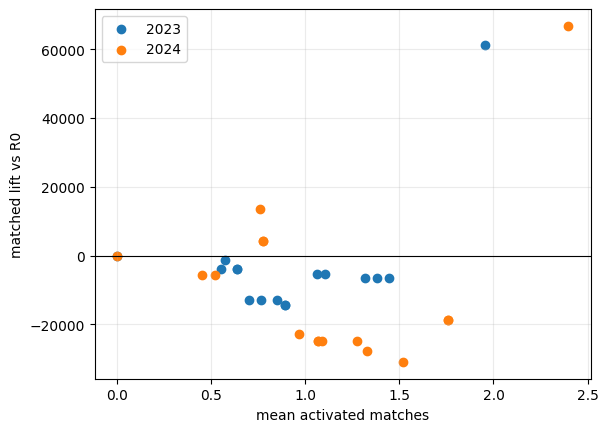

In [4]:
for year,g in performance.groupby('issue_year'):
    plt.scatter(g.mean_activated_changes,g.matched_lift_r0_cny,label=str(year))
plt.axhline(0,color='black',lw=.8); plt.grid(alpha=.25); plt.legend(); plt.xlabel('mean activated matches'); plt.ylabel('matched lift vs R0'); plt.show()

In [5]:
risk[risk.arm.isin(['R0','R3_CORRECTED',selected])]

,arm,issue_year,max_drawdown_fraction,max_consecutive_losing_issues,worst_rolling_5_cny,worst_rolling_10_cny,worst_rolling_20_cny,max_completed_recovery_issues,terminal_underwater_issues
6,R0,2023,0.259624,12,-5120,-10240.000000,-17626.074799,0,43
7,R0,2024,0.116387,7,-5120,-8853.606761,-13180.175749,16,29
8,R3_CORRECTED,2023,0.131232,21,-5120,-10240.000000,-20064.385379,4,41
9,R3_CORRECTED,2024,0.197970,10,-5120,-10240.000000,-11491.968309,38,1
16,RAW_Q80,2023,0.326413,26,-5120,-10240.000000,-20064.385379,0,44
17,RAW_Q80,2024,0.184261,8,-5120,-9201.260550,-14008.053339,0,58
